# Field Shift · Phase 2 — Validation (2018–2022)

The Phase 1 models are evaluated **frozen** (loaded from `artifacts/phase1_training/`, nothing refit) on the years
2018–2022, against the same simple baselines, with **95 % confidence intervals** for every metric. The acceptance criteria
were written in `docs/ML_PHASE1_TRAINING.md` §10 *before* these years were loaded; this notebook only applies them.
2017 is read only as history for the lags of January 2018 (its targets are not evaluated). Testing years (2023–2026) are
not loaded.

Results and reading: `docs/ML_PHASE2_VALIDATION.md`.

## 1. Environment and the pre-registered criteria

In [1]:
import os, sys, json, platform, hashlib
from pathlib import Path
import numpy as np, pandas as pd, scipy, sklearn, xgboost as xgb, matplotlib
import matplotlib.pyplot as plt

ML_DIR = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ML_DIR))
from fs_ml import data as D, features as F, evaluate as E

SEED = 42
np.random.seed(SEED)
pd.set_option("display.width", 170, "display.max_columns", 30)
SPLITS = {"training": (1998, 2017), "validation": (2018, 2022), "testing": (2023, 2026)}
VAL = SPLITS["validation"]
LOAD = (VAL[0] - 1, VAL[1])          # 2017 only as lag history
CAL, CHK = (2018, 2020), (2021, 2022)  # intervals: calibrate on CAL, check on CHK
N_BOOT, BLOCK_DEG = 1000, 0.2
P1 = ML_DIR / "artifacts" / "phase1_training"
ART = ML_DIR / "artifacts" / "phase2_validation"; ART.mkdir(parents=True, exist_ok=True)

# Written in docs/ML_PHASE1_TRAINING.md §10 before this notebook existed. Do not edit after seeing results.
CRITERIA = {
    "sm_root_monthly": {"A_skill_min": 0.20, "C_rmse_max": 0.04, "D_abs_bias_max": 0.01},
    "ndvi_quarterly": {"A_skill_min": 0.10, "C_rmse_max": None, "D_abs_bias_max": 0.03},
    "F_coverage_90": (0.87, 0.93),
}
VERSIONS = {"python": platform.python_version(), "numpy": np.__version__, "pandas": pd.__version__,
            "scipy": scipy.__version__, "xgboost": xgb.__version__}
VERSIONS

{'python': '3.14.6',
 'numpy': '2.5.4',
 'pandas': '3.1.1',
 'scipy': '1.18.1',
 'xgboost': '3.4.1'}

## 2. Frozen Phase 1 models

In [2]:
MODELS = {}
for name in ["sm_root_monthly", "ndvi_quarterly"]:
    d = P1 / name
    meta = json.loads((d / "metadata.json").read_text()); prep = json.loads((d / "preprocessing.json").read_text())
    m = xgb.XGBRegressor(); m.load_model(d / "model.ubj")
    assert m.get_booster().feature_names == prep["feature_names_in_order"]
    by_cell = pd.read_parquet(d / "baseline_climatology_by_cell.parquet")
    by_season = pd.read_parquet(d / "baseline_climatology_by_season.parquet")
    keys = list(by_cell.columns[:-1]); season = by_season.columns[0]
    MODELS[name] = {"model": m, "meta": meta, "prep": prep, "features": prep["feature_names_in_order"],
                    "target": meta["target"]["column"], "unit": meta["target"]["unit"],
                    "clim": {"by_cell": by_cell.set_index(keys)["climatology"], "by_season": by_season.set_index(season)["climatology"],
                             "keys": keys, "season": season},
                    "model_sha256": D.sha256(d / "model.ubj")}
    print(name, "| target", MODELS[name]["target"], "| trees", meta["best_number_of_trees"], "| sha256", MODELS[name]["model_sha256"][:16])

sm_root_monthly | target sm_root_m3m3 | trees 1122 | sha256 a4bbaf1397c43e2c
ndvi_quarterly | target ndvi | trees 89 | sha256 effe57ea2506d509


## 3. New NASA POWER files (2018–2022): inventory and consistency with the training files

In [3]:
power, rows = {}, []
for p in ["t2m", "rh2m", "ws2m", "allsky"]:
    df, info = D.load_power(f"power_{p}_2018_2022", VAL)
    ref, _ = D.load_power(f"power_{p}", SPLITS["training"])
    col = df.columns[-1]
    pts, ref_pts = set(map(tuple, df[["power_lat", "power_lon"]].drop_duplicates().values)), set(map(tuple, ref[["power_lat", "power_lon"]].drop_duplicates().values))
    power[p] = df
    rows.append({"file": D.RAW_FILES[f"power_{p}_2018_2022"].split("/")[-1], "parameter": info["parameter"],
                 "dates": info["header"].splitlines()[2].split(": ")[1], "rows": info["rows_wide"], "duplicates": info["duplicate_rows"],
                 "-999": info["missing_-999"], "same_grid_as_training": pts == ref_pts, "years": f"{df.date.dt.year.min()}-{df.date.dt.year.max()}",
                 "range_2018_2022": f"{df[col].min():.2f}..{df[col].max():.2f}", "range_1998_2017": f"{ref[col].min():.2f}..{ref[col].max():.2f}"})
pd.DataFrame(rows)

,file,parameter,dates,rows,duplicates,-999,same_grid_as_training,years,range_2018_2022,range_1998_2017
0,Temperature at 2 Meters_Monthly_2018_2022.csv,T2M,01/01/2018 through 12/31/2022 in LST,100,0,0,True,2018-2022,12.87..28.97,12.13..29.35
1,Relative Humidity at 2 Meters_Monthly_2018_202...,RH2M,01/01/2018 through 12/31/2022 in LST,100,0,0,True,2018-2022,47.50..97.38,46.42..97.13
2,Wind Speed at 2 Meters_Monthly_2018_2022.csv,WS2M,01/01/2018 through 12/31/2022 in LST,100,0,0,True,2018-2022,1.00..5.75,1.02..6.02
3,All Sky Surface Shortwave Downward Irradiance_...,ALLSKY_SFC_SW_DWN,01/01/2018 through 12/31/2022 in LST,30,0,0,True,2018-2022,10.30..24.65,9.20..25.80


## 4. GEE tables for 2017–2022 (2017 = lag history only)

In [4]:
monthly, info_m = D.load_gee_monthly(LOAD); veg, info_q = D.load_gee_quarterly(LOAD)
print("monthly:", info_m); print("quarterly:", info_q)
print("monthly missing values:", monthly.isna().sum().to_dict())
cov = veg[veg.year.between(*VAL)].groupby(["year", "quarter"]).size().unstack("quarter")
print("Cells with NDVI per quarter, 2018-2022 (of 2585):"); cov

monthly: {'rows_total': 1089554, 'rows_kept': 226728, 'rows_outside_window_not_used': 862826, 'index_prefix_matches_month': True}
quarterly: {'rows_total': 181580, 'rows_kept': 60500, 'rows_outside_window_not_used': 121080}
monthly missing values: {'cell_id': 0, 'date': 0, 'rain_mm': 0, 't2m_c': 1656, 'pet_mm': 1656, 'sm_surface_m3m3': 1656, 'sm_root_m3m3': 1656}
Cells with NDVI per quarter, 2018-2022 (of 2585):


quarter,1,2,3,4
year,,,,
2018,2396,2577,2549,2556
2019,2449,2562,2574,2534
2020,2467,2557,2582,2463
2021,2566,2557,2480,2538
2022,2521,2561,2426,2562


## 5. Validation tables, built with the same code as Training

In [5]:
gaez = {k: D.load_gaez(k)[0] for k in F.GAEZ_FEATURES}
merra = power["t2m"].merge(power["rh2m"], on=["power_lat", "power_lon", "date"]).merge(power["ws2m"], on=["power_lat", "power_lon", "date"])
ceres = power["allsky"]
cells = F.static_cells(D.cells_from_ids(monthly.cell_id), gaez, merra[["power_lat", "power_lon"]].drop_duplicates().reset_index(drop=True),
                       ceres[["power_lat", "power_lon"]].drop_duplicates().reset_index(drop=True))
p1_cells = ML_DIR / "data" / "processed" / "cells_static.parquet"
if p1_cells.exists():
    a = pd.read_parquet(p1_cells).set_index("cell_id"); b = cells.set_index("cell_id")
    cols = ["lat", "lon", *F.SOIL, "merra_lat", "merra_lon", "ceres_lat", "ceres_lon"]
    print("static attributes identical to Training:", a.loc[b.index, cols].equals(b[cols]))
cells["province"] = D.provinces_of(cells)
print(cells.province.value_counts().to_dict())
cells["block"] = E.spatial_blocks(cells.lat, cells.lon, BLOCK_DEG)
print("spatial blocks of", BLOCK_DEG, "deg:", cells.block.nunique())

monthly_panel = F.build_monthly_panel(monthly, cells.drop(columns=["province", "block"]), merra, ceres)
quarterly_panel = F.build_quarterly_panel(monthly_panel, veg)
extra = cells.set_index("cell_id")[["province", "block"]]
monthly_panel = monthly_panel.join(extra, on="cell_id"); quarterly_panel = quarterly_panel.join(extra, on="cell_id")
monthly_panel["season"] = np.where(monthly_panel.month <= 4, "wet Jan-Apr", "dry May-Dec")
quarterly_panel["season"] = "Q" + quarterly_panel.quarter.astype(str)
EVAL = {"sm_root_monthly": monthly_panel, "ndvi_quarterly": quarterly_panel}
for name, df in EVAL.items():
    t = MODELS[name]["target"]
    v = df[df.year.between(*VAL) & df[t].notna()]
    print(name, "| validation rows with target:", len(v), "| cells:", v.cell_id.nunique(),
          "| POWER missing in validation rows:", int(v[["power_rh2m_pct" if name.startswith("sm") else "q_power_rh2m_pct"]].isna().sum().iloc[0]))

static attributes identical to Training: True
{'Lambayeque': 1199, 'outside': 1176, 'Chiclayo': 518, 'Ferreñafe': 256}
spatial blocks of 0.2 deg: 61


sm_root_monthly | validation rows with target: 187560 | cells: 3126 | POWER missing in validation rows: 0
ndvi_quarterly | validation rows with target: 50477 | cells: 2584 | POWER missing in validation rows: 0


## 6. Predictions and baselines

In [6]:
V = {}
for name, M in MODELS.items():
    df = EVAL[name]; t = M["target"]
    v = df[df.year.between(*VAL) & df[t].notna()].reset_index(drop=True)
    pred = M["model"].predict(v[M["features"]])
    clim = E.predict_climatology(M["clim"], v)
    lag = "sm_root_m3m3_lag1" if name.startswith("sm") else "ndvi_lag1"
    pers = np.where(v[lag].isna(), clim, v[lag])
    V[name] = {"rows": v, "y": v[t].to_numpy(), "preds": {"XGBoost": pred, "climatology": clim, "persistence": pers}}
    rm = {k: E.regression_metrics(v[t], p)["RMSE"] for k, p in V[name]["preds"].items()}
    V[name]["best_baseline"] = min(["climatology", "persistence"], key=rm.get)
    print(name, {k: round(x, 4) for k, x in rm.items()}, "-> best baseline:", V[name]["best_baseline"])

sm_root_monthly {'XGBoost': 0.0125, 'climatology': 0.0317, 'persistence': 0.026} -> best baseline: persistence


ndvi_quarterly {'XGBoost': 0.1031, 'climatology': 0.1256, 'persistence': 0.1564} -> best baseline: climatology


## 7. Metrics with 95 % confidence intervals (block bootstrap)

Whole 0.2° spatial blocks are resampled with their five years, 1,000 times.

In [7]:
def ci_table(name, mask=None):
    R = V[name]; m = slice(None) if mask is None else mask
    return E.block_bootstrap(R["y"][m], {k: p[m] for k, p in R["preds"].items()}, R["rows"]["block"].to_numpy()[m],
                             reference="XGBoost", n_boot=N_BOOT, seed=SEED)
OVERALL = {}
for name in V:
    OVERALL[name] = ci_table(name)
    print(f"\n=== {name} ({MODELS[name]['unit']}) — validation 2018-2022, n = {len(V[name]['y'])}")
    display(OVERALL[name].round(4))
    if name.startswith("sm"):
        y, p = V[name]["y"], V[name]["preds"]["XGBoost"]
        print("MAPE (%):", round(float(np.mean(np.abs(p - y) / y) * 100), 2))


=== sm_root_monthly (m3/m3) — validation 2018-2022, n = 187560


,model,metric,value,ci_low,ci_high
0,XGBoost,MAE,0.0073,0.0061,0.0084
1,XGBoost,RMSE,0.0125,0.0110,0.0139
2,XGBoost,R2,0.9860,0.9813,0.9895
3,XGBoost,bias,-0.0004,-0.0009,0.0000
4,XGBoost,skill vs climatology,0.6045,0.5725,0.6341
5,XGBoost,skill vs persistence,0.5190,0.4777,0.5538
6,climatology,MAE,0.0212,0.0189,0.0236
7,climatology,RMSE,0.0317,0.0280,0.0352
8,climatology,R2,0.9106,0.8800,0.9322
9,climatology,bias,0.0074,0.0028,0.0115


MAPE (%): 3.67

=== ndvi_quarterly (index) — validation 2018-2022, n = 50477


,model,metric,value,ci_low,ci_high
0,XGBoost,MAE,0.0747,0.0698,0.0794
1,XGBoost,RMSE,0.1031,0.0968,0.1089
2,XGBoost,R2,0.6624,0.6021,0.7158
3,XGBoost,bias,0.0015,-0.0059,0.0083
4,XGBoost,skill vs climatology,0.1793,0.1000,0.2521
5,XGBoost,skill vs persistence,0.3407,0.2823,0.3867
6,climatology,MAE,0.0887,0.0802,0.0983
7,climatology,RMSE,0.1256,0.1112,0.1412
8,climatology,R2,0.4987,0.3624,0.6076
9,climatology,bias,-0.0312,-0.0458,-0.0187


In [8]:
def by_group(name, col):
    R = V[name]; best = R["best_baseline"]; out = []
    for g in sorted(R["rows"][col].unique(), key=str):
        mask = (R["rows"][col] == g).to_numpy()
        t = ci_table(name, mask).set_index(["model", "metric"])
        out.append({col: g, "n": int(mask.sum()), "RMSE": t.loc[("XGBoost", "RMSE"), "value"],
                    f"RMSE {best}": t.loc[(best, "RMSE"), "value"], "bias": t.loc[("XGBoost", "bias"), "value"],
                    "R2": t.loc[("XGBoost", "R2"), "value"], "skill": t.loc[("XGBoost", f"skill vs {best}"), "value"],
                    "skill_ci_low": t.loc[("XGBoost", f"skill vs {best}"), "ci_low"], "skill_ci_high": t.loc[("XGBoost", f"skill vs {best}"), "ci_high"]})
    return pd.DataFrame(out)
GROUPS = {}
for name in V:
    GROUPS[name] = {col: by_group(name, col) for col in ["year", "province", "season"]}
    for col, tab in GROUPS[name].items():
        print(f"\n{name} by {col} (skill vs {V[name]['best_baseline']}, 95% CI)"); display(tab.round(4))


sm_root_monthly by year (skill vs persistence, 95% CI)


,year,n,RMSE,RMSE persistence,bias,R2,skill,skill_ci_low,skill_ci_high
0,2018,37512,0.0125,0.0240,-0.0003,0.9855,0.4778,0.3542,0.5741
1,2019,37512,0.0109,0.0315,0.0001,0.9894,0.6535,0.6276,0.6761
2,2020,37512,0.0114,0.0221,-0.0011,0.9882,0.4829,0.4012,0.5398
3,2021,37512,0.0134,0.0260,-0.0012,0.9844,0.4832,0.4301,0.5269
4,2022,37512,0.0141,0.0257,0.0004,0.9825,0.4520,0.4132,0.4822



sm_root_monthly by province (skill vs persistence, 95% CI)


,province,n,RMSE,RMSE persistence,bias,R2,skill,skill_ci_low,skill_ci_high
0,Chiclayo,29700,0.0125,0.0173,0.0005,0.9651,0.2761,0.1640,0.3488
1,Ferreñafe,15360,0.0141,0.0329,-0.0014,0.9750,0.5718,0.4744,0.6570
2,Lambayeque,71940,0.0106,0.0199,-0.0001,0.9790,0.4683,0.4073,0.5015
3,outside,70560,0.0139,0.0322,-0.0009,0.9827,0.5675,0.5314,0.5939



sm_root_monthly by season (skill vs persistence, 95% CI)


,season,n,RMSE,RMSE persistence,bias,R2,skill,skill_ci_low,skill_ci_high
0,dry May-Dec,125040,0.0091,0.0232,-0.0017,0.9907,0.6064,0.5784,0.6285
1,wet Jan-Apr,62520,0.0174,0.0310,0.0021,0.9797,0.4371,0.4008,0.4734


... (2 outputs left out)


ndvi_quarterly by province (skill vs climatology, 95% CI)


,province,n,RMSE,RMSE climatology,bias,R2,skill,skill_ci_low,skill_ci_high
0,Chiclayo,9382,0.1052,0.1271,-0.0037,0.5481,0.1726,0.0647,0.3020
1,Ferreñafe,3880,0.0994,0.1008,-0.0049,0.6559,0.0137,-0.0386,0.0481
2,Lambayeque,21175,0.1005,0.1323,0.0051,0.5899,0.2406,0.1059,0.3325
3,outside,16040,0.1061,0.1209,0.0013,0.6426,0.1230,0.0505,0.1799



ndvi_quarterly by season (skill vs climatology, 95% CI)


,season,n,RMSE,RMSE climatology,bias,R2,skill,skill_ci_low,skill_ci_high
0,Q1,12399,0.1124,0.1372,-0.0096,0.5633,0.1810,0.1002,0.2598
1,Q2,12814,0.1225,0.1395,0.0129,0.6424,0.1223,0.0391,0.2069
2,Q3,12611,0.0939,0.1173,-0.0035,0.6033,0.1998,0.1170,0.2680
3,Q4,12653,0.0777,0.1051,0.0057,0.7315,0.2605,0.1679,0.3425


## 8. Prediction intervals: recalibrated on 2018–2020, checked on 2021–2022

In [9]:
INTERVALS = {}
for name, R in V.items():
    yr = R["rows"].year.to_numpy(); res = R["preds"]["XGBoost"] - R["y"]; blk = R["rows"]["block"].to_numpy()
    cal, chk = (yr >= CAL[0]) & (yr <= CAL[1]), (yr >= CHK[0]) & (yr <= CHK[1])
    p1 = MODELS[name]["meta"]["provisional_intervals"]["half_width"]
    rows = []
    for c in [0.80, 0.90, 0.95]:
        k = f"{int(c*100)}%"
        h = E.conformal_halfwidth(res[cal], c)
        cv, lo, hi = E.coverage_ci(np.abs(res[chk]) <= h, blk[chk])
        cv1, lo1, hi1 = E.coverage_ci(np.abs(res) <= p1[k], blk)
        rows.append({"nominal": k, "half_width_phase1": p1[k], "coverage_2018_2022_of_phase1_width": cv1, "ci": f"{lo1:.3f}-{hi1:.3f}",
                     "half_width_cal_2018_2020": h, "coverage_2021_2022": cv, "ci ": f"{lo:.3f}-{hi:.3f}"})
    glob_tab = pd.DataFrame(rows)
    # same check with one width per season (Mondrian conformal), as a diagnostic
    seas = R["rows"]["season"].to_numpy(); srows = []
    for s in sorted(set(seas)):
        h = E.conformal_halfwidth(res[cal & (seas == s)], 0.90)
        m = chk & (seas == s)
        cv, lo, hi = E.coverage_ci(np.abs(res[m]) <= h, blk[m])
        srows.append({"season": s, "half_width_90": h, "coverage_2021_2022": cv, "ci_low": lo, "ci_high": hi})
    seas_tab = pd.DataFrame(srows)
    final = {f"{int(c*100)}%": E.conformal_halfwidth(res, c) for c in [0.80, 0.90, 0.95]}
    final_season = {s: E.conformal_halfwidth(res[seas == s], 0.90) for s in sorted(set(seas))}
    INTERVALS[name] = {"global": glob_tab, "by_season": seas_tab, "final_global_2018_2022": final, "final_by_season_90_2018_2022": final_season}
    print(f"\n=== {name}"); display(glob_tab.round(4)); print("one 90% width per season:"); display(seas_tab.round(4))


=== sm_root_monthly


,nominal,half_width_phase1,coverage_2018_2022_of_phase1_width,ci,half_width_cal_2018_2020,coverage_2021_2022,ci
0,80%,0.0164,0.8794,0.851-0.907,0.0099,0.7606,0.714-0.809
1,90%,0.0314,0.9589,0.948-0.970,0.0174,0.8722,0.844-0.899
2,95%,0.0500,0.9902,0.987-0.993,0.0267,0.9340,0.917-0.949


one 90% width per season:


,season,half_width_90,coverage_2021_2022,ci_low,ci_high
0,dry May-Dec,0.0123,0.8840,0.8507,0.9157
1,wet Jan-Apr,0.0264,0.8514,0.8062,0.8929



=== ndvi_quarterly


,nominal,half_width_phase1,coverage_2018_2022_of_phase1_width,ci,half_width_cal_2018_2020,coverage_2021_2022,ci
0,80%,0.1631,0.8902,0.875-0.906,0.1157,0.7664,0.740-0.792
1,90%,0.2524,0.9694,0.962-0.976,0.1641,0.8796,0.860-0.898
2,95%,0.3312,0.9910,0.987-0.994,0.2132,0.9400,0.926-0.952


one 90% width per season:


,season,half_width_90,coverage_2021_2022,ci_low,ci_high
0,Q1,0.1842,0.9015,0.8703,0.9290
1,Q2,0.1983,0.8828,0.8536,0.9107
2,Q3,0.1371,0.8375,0.7992,0.8702
3,Q4,0.1162,0.8733,0.8471,0.8960


## 9. Inputs outside the training range

In [10]:
OOD = {}
for name, R in V.items():
    X = R["rows"][MODELS[name]["features"]]; b = MODELS[name]["prep"]["training_feature_bounds"]
    soft, hard = E.out_of_range(X, b), E.out_of_range(X, b, strict=True)
    per_feat = {c: float(((X[c] < b[c]["p01"]) | (X[c] > b[c]["p99"])).mean()) for c in X.columns}
    y, p = R["y"], R["preds"]["XGBoost"]
    OOD[name] = {"share_outside_p01_p99": float(soft.mean()), "share_outside_min_max": float(hard.mean()),
                 "RMSE_inside": E.regression_metrics(y[~soft.values], p[~soft.values])["RMSE"],
                 "RMSE_outside": E.regression_metrics(y[soft.values], p[soft.values])["RMSE"] if soft.any() else None,
                 "top_features": dict(sorted(per_feat.items(), key=lambda kv: -kv[1])[:5])}
    print(name, json.dumps(OOD[name], indent=1))

sm_root_monthly {
 "share_outside_p01_p99": 0.15453721475794413,
 "share_outside_min_max": 0.0032682874813393047,
 "RMSE_inside": 0.012853974542181415,
 "RMSE_outside": 0.010554957823998814,
 "top_features": {
  "power_rh2m_pct": 0.033887822563446364,
  "t2m_c": 0.03137662614629985,
  "pet_mm": 0.02303796118575389,
  "pet_mm_lag1": 0.022611431008743868,
  "sm_root_m3m3_lag1": 0.016565365749626786
 }
}
ndvi_quarterly {
 "share_outside_p01_p99": 0.15977573944568813,
 "share_outside_min_max": 0.014481843215722013,
 "RMSE_inside": 0.10107104159488992,
 "RMSE_outside": 0.11313184282059215,
 "top_features": {
  "q_power_rh2m_pct": 0.03974087208035343,
  "q_t2m_c": 0.0355805614438259,
  "q_pet_mm": 0.022842086494839233,
  "q_power_ws2m_ms": 0.019394971967430712,
  "ndvi_lag4": 0.01897894090377796
 }
}


## 10. Acceptance criteria

In [11]:
DECISION = {}
for name, R in V.items():
    c = CRITERIA[name]; best = R["best_baseline"]
    t = OVERALL[name].set_index(["model", "metric"])
    sk = t.loc[("XGBoost", f"skill vs {best}")]; rmse = t.loc[("XGBoost", "RMSE")]; bias = t.loc[("XGBoost", "bias")]
    prov = GROUPS[name]["province"]; prov = prov[prov.province != "outside"]
    worst_year = GROUPS[name]["year"].skill.min(); worst_prov = prov.skill.min()
    cov = INTERVALS[name]["global"].set_index("nominal").loc["90%", "coverage_2021_2022"]
    lo, hi = CRITERIA["F_coverage_90"]
    rows = [
        ("A", f"skill vs {best} >= {c['A_skill_min']}", f"{sk.value:.3f} [{sk.ci_low:.3f}, {sk.ci_high:.3f}]", sk.value >= c["A_skill_min"]),
        ("B", "lower 95% CI of that skill > 0", f"{sk.ci_low:.3f}", sk.ci_low > 0),
        ("C", f"RMSE <= {c['C_rmse_max']}" if c["C_rmse_max"] else "RMSE (report only)",
         f"{rmse.value:.4f} [{rmse.ci_low:.4f}, {rmse.ci_high:.4f}]", (rmse.value <= c["C_rmse_max"]) if c["C_rmse_max"] else None),
        ("D", f"|bias| <= {c['D_abs_bias_max']}", f"{bias.value:.4f} [{bias.ci_low:.4f}, {bias.ci_high:.4f}]", abs(bias.value) <= c["D_abs_bias_max"]),
        ("E", "skill >= 0 in every year and province", f"worst year {worst_year:.3f}, worst province {worst_prov:.3f}", min(worst_year, worst_prov) >= 0),
        ("F", f"90% interval coverage 2021-2022 in [{lo}, {hi}]", f"{cov:.3f}", lo <= cov <= hi),
        ("G", "share of rows outside training p01-p99 (report)", f"{OOD[name]['share_outside_p01_p99']:.3f}", None),
    ]
    tab = pd.DataFrame(rows, columns=["criterion", "rule", "result", "pass"])
    a_b = bool(tab.loc[tab.criterion.isin(["A", "B"]), "pass"].all())
    others = tab.loc[tab.criterion.isin(["C", "D", "E", "F"]), "pass"].dropna()
    if not a_b:
        verdict = "REJECT: the simpler baseline wins. The app shows the baseline instead."
    elif others.all():
        verdict = "ACCEPT: can feed the simulator, with intervals recalibrated on 2018-2022."
    else:
        verdict = "FIX: worth keeping, but fails " + ", ".join(tab.loc[tab["pass"] == False, "criterion"]) + ". Fix with Validation only, then re-check."
    DECISION[name] = {"table": tab, "verdict": verdict}
    print(f"\n=== {name}: {verdict}"); display(tab)


=== sm_root_monthly: ACCEPT: can feed the simulator, with intervals recalibrated on 2018-2022.


,criterion,rule,result,pass
0,A,skill vs persistence >= 0.2,"0.519 [0.478, 0.554]",True
1,B,lower 95% CI of that skill > 0,0.478,True
2,C,RMSE <= 0.04,"0.0125 [0.0110, 0.0139]",True
3,D,|bias| <= 0.01,"-0.0004 [-0.0009, 0.0000]",True
4,E,skill >= 0 in every year and province,"worst year 0.452, worst province 0.276",True
5,F,"90% interval coverage 2021-2022 in [0.87, 0.93]",0.872,True
6,G,share of rows outside training p01-p99 (report),0.155,None



=== ndvi_quarterly: ACCEPT: can feed the simulator, with intervals recalibrated on 2018-2022.


,criterion,rule,result,pass
0,A,skill vs climatology >= 0.1,"0.179 [0.100, 0.252]",True
1,B,lower 95% CI of that skill > 0,0.100,True
2,C,RMSE (report only),"0.1031 [0.0968, 0.1089]",None
3,D,|bias| <= 0.03,"0.0015 [-0.0059, 0.0083]",True
4,E,skill >= 0 in every year and province,"worst year 0.063, worst province 0.014",True
5,F,"90% interval coverage 2021-2022 in [0.87, 0.93]",0.880,True
6,G,share of rows outside training p01-p99 (report),0.160,None


## 11. Figures

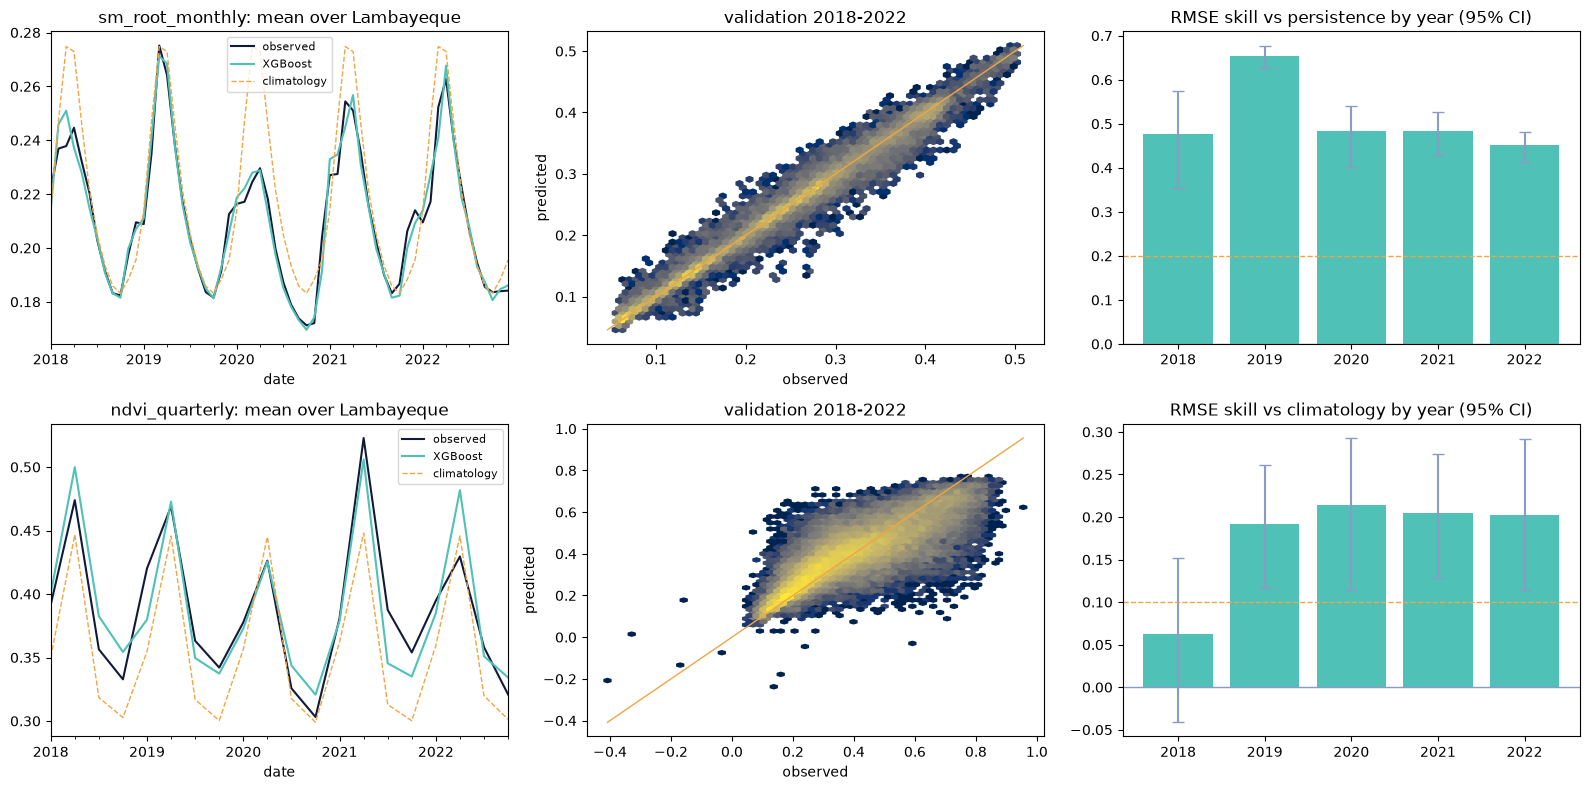

In [12]:
fig, ax = plt.subplots(2, 3, figsize=(16, 8))
for row, (name, R) in zip(ax, V.items()):
    v = R["rows"].assign(pred=R["preds"]["XGBoost"], clim=R["preds"]["climatology"], obs=R["y"])
    if "date" not in v: v["date"] = pd.to_datetime(dict(year=v.year, month=(v.quarter - 1) * 3 + 1, day=1))
    ts = v.groupby("date")[["obs", "pred", "clim"]].mean()
    ts.obs.plot(ax=row[0], color="#121A3A", lw=1.5, label="observed")
    ts.pred.plot(ax=row[0], color="#4FC1B6", lw=1.5, label="XGBoost"); ts.clim.plot(ax=row[0], color="#F2A541", lw=1, ls="--", label="climatology")
    row[0].set_title(f"{name}: mean over Lambayeque"); row[0].legend(fontsize=8)
    row[1].hexbin(v.obs, v.pred, gridsize=60, bins="log", cmap="cividis")
    lim = [min(v.obs.min(), v.pred.min()), max(v.obs.max(), v.pred.max())]; row[1].plot(lim, lim, color="#F2A541", lw=1)
    row[1].set_xlabel("observed"); row[1].set_ylabel("predicted"); row[1].set_title("validation 2018-2022")
    g = GROUPS[name]["year"]
    row[2].bar(g.year.astype(str), g.skill, color="#4FC1B6",
               yerr=[g.skill - g.skill_ci_low, g.skill_ci_high - g.skill], capsize=4, ecolor="#8C9BC4")
    row[2].axhline(0, color="#8C9BC4", lw=1); row[2].axhline(CRITERIA[name]["A_skill_min"], color="#F2A541", lw=1, ls="--")
    row[2].set_title(f"RMSE skill vs {R['best_baseline']} by year (95% CI)")
plt.tight_layout(); fig.savefig(ART / "phase2_validation.png", dpi=110); plt.show()

## 12. Saving the validation report

In [13]:
summary = {"phase": "2 - validation", "years": VAL, "lag_history_year": LOAD[0], "testing_used": False, "models_refit": False,
           "bootstrap": {"n": N_BOOT, "block_deg": BLOCK_DEG, "level": 0.95, "seed": SEED}, "library_versions": VERSIONS,
           "new_files": [D.RAW_FILES[f"power_{p}_2018_2022"] for p in ["t2m", "rh2m", "ws2m", "allsky"]],
           "models": {}}
for name in V:
    out = ART / name; out.mkdir(exist_ok=True)
    OVERALL[name].to_csv(out / "metrics_ci.csv", index=False)
    for col, tab in GROUPS[name].items(): tab.to_csv(out / f"metrics_by_{col}.csv", index=False)
    INTERVALS[name]["global"].to_csv(out / "intervals_check.csv", index=False)
    INTERVALS[name]["by_season"].to_csv(out / "intervals_by_season_check.csv", index=False)
    DECISION[name]["table"].to_csv(out / "criteria.csv", index=False)
    rep = {"model_sha256": MODELS[name]["model_sha256"], "n_rows": int(len(V[name]["y"])), "best_baseline": V[name]["best_baseline"],
           "verdict": DECISION[name]["verdict"], "criteria": DECISION[name]["table"].to_dict("records"),
           "metrics_ci": OVERALL[name].to_dict("records"), "out_of_range": OOD[name],
           "intervals_final_2018_2022": {"global_half_width": INTERVALS[name]["final_global_2018_2022"],
                                         "by_season_half_width_90": INTERVALS[name]["final_by_season_90_2018_2022"],
                                         "note": "For Testing and the app only if the model is accepted. Coverage is checked once on 2023-2026."}}
    (out / "validation_report.json").write_text(json.dumps(rep, indent=2, default=lambda o: o.item() if hasattr(o, "item") else str(o)))
    summary["models"][name] = {"verdict": rep["verdict"], "best_baseline": rep["best_baseline"]}
(ART / "phase2_summary.json").write_text(json.dumps(summary, indent=2, default=str))
for f in sorted(ART.rglob("*")):
    if f.is_file(): print(f.relative_to(ML_DIR))
summary["models"]

artifacts/phase2_validation/ndvi_quarterly/criteria.csv
artifacts/phase2_validation/ndvi_quarterly/intervals_by_season_check.csv
artifacts/phase2_validation/ndvi_quarterly/intervals_check.csv
artifacts/phase2_validation/ndvi_quarterly/metrics_by_province.csv
artifacts/phase2_validation/ndvi_quarterly/metrics_by_season.csv
artifacts/phase2_validation/ndvi_quarterly/metrics_by_year.csv
artifacts/phase2_validation/ndvi_quarterly/metrics_ci.csv
artifacts/phase2_validation/ndvi_quarterly/validation_report.json
artifacts/phase2_validation/phase2_summary.json
artifacts/phase2_validation/phase2_validation.png
artifacts/phase2_validation/sm_root_monthly/criteria.csv
artifacts/phase2_validation/sm_root_monthly/intervals_by_season_check.csv
artifacts/phase2_validation/sm_root_monthly/intervals_check.csv
artifacts/phase2_validation/sm_root_monthly/metrics_by_province.csv
artifacts/phase2_validation/sm_root_monthly/metrics_by_season.csv
artifacts/phase2_validation/sm_root_monthly/metrics_by_year.cs

{'sm_root_monthly': {'verdict': 'ACCEPT: can feed the simulator, with intervals recalibrated on 2018-2022.',
  'best_baseline': 'persistence'},
 'ndvi_quarterly': {'verdict': 'ACCEPT: can feed the simulator, with intervals recalibrated on 2018-2022.',
  'best_baseline': 'climatology'}}

**Validation stops here.** Testing (2023–2026) runs once, after the team decides what to do with each verdict.